In [1]:
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.ndimage import gaussian_filter
from skimage.color import label2rgb
from skimage.draw import ellipse
from skimage.measure import label, regionprops, regionprops_table
from skimage.transform import rotate
import warnings

from scipy.stats import kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from skimage.segmentation import expand_labels, watershed
import os
import random

import warnings
warnings.filterwarnings('ignore')

import muspan as ms

(<Figure size 800x500 with 2 Axes>, <Axes: >)

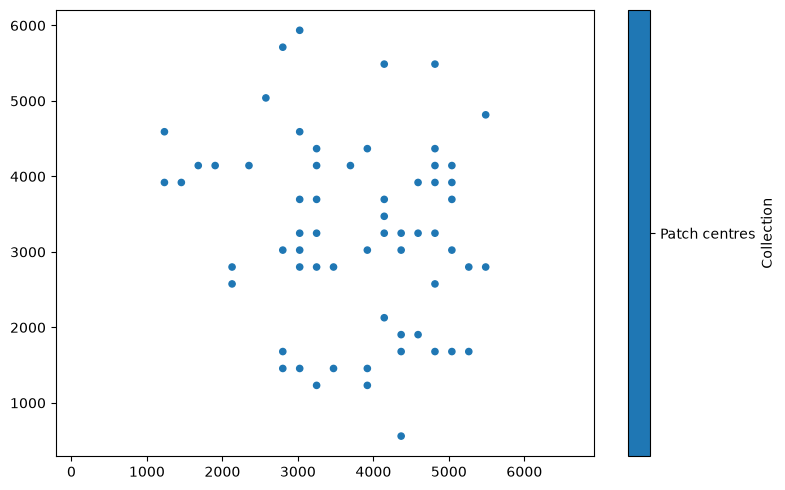

In [4]:
domain = ms.domain('dist_dom')
points = np.asarray([dist_df['x'], dist_df['y']])
domain.add_points(points.T, 'Patch centres')
import matplotlib.pyplot as plt

# Create a figure for visualisation
plt.figure(figsize=(8, 5))

# Visualise the domain
ms.visualise.visualise(domain, ax=plt.gca())

In [194]:
# Extract the 'Cell type' column from the dataframe
celltype_array = dist_df['cluster']

# Add the cell type labels to the domain
domain.add_labels('cluster', celltype_array)

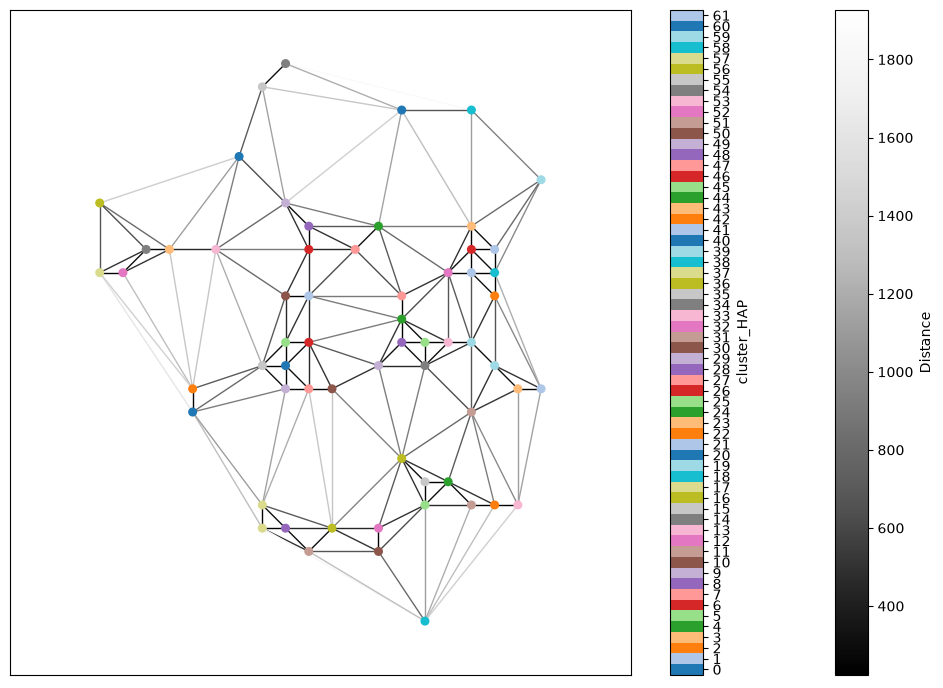

In [10]:
# Generate the 'Centroid Delaunay' network for the example domain
import matplotlib.pyplot as plt
import matplotlib

plt.cm.get_cmap = matplotlib.colormaps.get_cmap

ms.networks.generate_network(
    domain,
    network_name='Centroid Delaunay',
    network_type='Delaunay',
    max_edge_distance=2000
)

# Visualise the generated network, coloring by 'Celltype'
ms.visualise.visualise_network(
    domain,
    network_name='Centroid Delaunay',
    visualise_kwargs=dict(color_by='cluster_HAP', marker_size=30),
    figure_kwargs=dict(figsize=(10, 7))
)

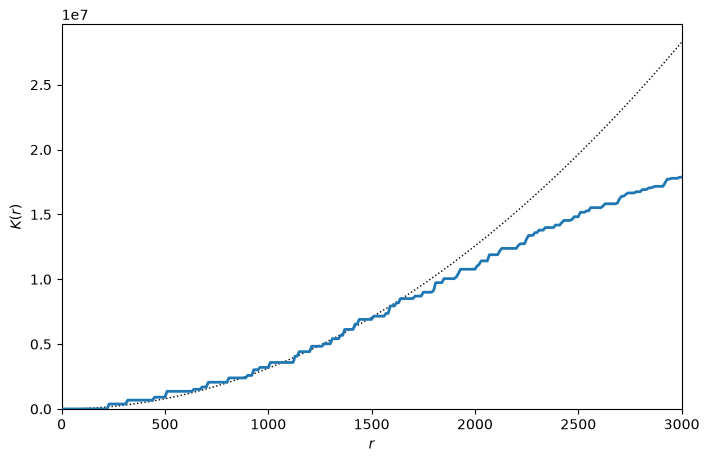

In [195]:
## This shows how clustered these patches are at various distances
radius,rip_K=ms.spatial_statistics.cross_k_function(domain,
                                                    population_A=('cluster', 'HAP'),
                                                    population_B=('cluster', 'HAP'),
                                                    max_R=3000,
                                                    visualise_output=True)


In [ ]:
### Now I am creating a function that will compare the high attention patches of a TMA to the low attention patches, measuring the clustering within a single sample

In [152]:
### Now the clark-evans function, it works within TMA's not across, that can be done with the Ripley's K
#### This needs a dataframe of points 

import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull, cKDTree
from scipy.stats import norm

def clark_evans(points, region_coords):
    """points: (n, 2) array. region_coords: (m, 2) array whose convex hull defines the area."""
    n = len(points)
    nn = cKDTree(points).query(points, k=2)[0][:, 1]   # nearest-neighbour distances
    hull = ConvexHull(region_coords)
    area, perim = hull.volume, hull.area                # in 2D: volume = area, area = perimeter
    expected = 0.5*np.sqrt(area/n) + (0.0514 + 0.041/np.sqrt(n))*perim/n   # Donnelly 1978
    sigma = np.sqrt(0.070*area/n**2 + 0.037*perim*np.sqrt(area/n**5))
    z = (nn.mean() - expected) / sigma
    return {"R": nn.mean()/expected, "z": z, "p": 2*norm.sf(abs(z)), "n": n, "area": area}

# per TMA
res = pd.DataFrame({
    t: clark_evans(cells.loc[cells.TMA == t, ["x", "y"]].to_numpy(),
                   region.loc[region.TMA == t, ["x", "y"]].to_numpy())
    for t in cells.TMA.unique()
}).T

In [157]:
results = []
for i in range(len(tmas)):
    tma = tmas[i]
    p_value, Z, estimated_area, R = clark_evans(df_HAP_bot, tma, sample_coords1)
    results.append({
        'TMA': tma,
        'p_value_bot': p_value,
        'Z_bot': Z,
        'estimated_area_bot': estimated_area,
        'R_bot': R
    })

clark_evans_bot = pd.DataFrame(results)

clark_evans_bot.head()

,TMA,p_value_bot,Z_bot,estimated_area_bot,R_bot
0,TMA9_20,0.790607,-0.265522,2.591584e+07,0.980372
1,TMA7_38,0.379744,0.878368,2.846190e+07,1.058311
2,TMA0_22,0.189874,1.310952,2.986503e+07,1.087028
3,TMA0_67,0.276066,-1.089199,3.740836e+07,0.925877
4,TMA5_94,0.374751,-0.887609,3.250899e+07,0.943317


In [173]:
results = []
for i in range(len(tmas)):
    tma = tmas[i]
    p_value, Z, estimated_area, R = clark_evans(df_HAP_top, tma, sample_coords1)
    results.append({
        'TMA': tma,
        'p_value_top': p_value,
        'Z_top': Z,
        'estimated_area_top': estimated_area,
        'R_top': R
    })

clark_evans_top = pd.DataFrame(results)

clark_evans_top.head()

,TMA,p_value_top,Z_top,estimated_area_top,R_top
0,TMA9_20,0.006516,-2.720607,2.591584e+07,0.798882
1,TMA7_38,0.373347,0.890222,2.846190e+07,1.059098
2,TMA0_22,0.020247,-2.321744,2.986503e+07,0.845870
3,TMA0_67,0.000140,-3.807348,3.740836e+07,0.740901
4,TMA5_94,0.517100,-0.647822,3.250899e+07,0.958630
